In [14]:
# Walk up to repo root (identified by README.md)
.root <- getwd()
while (!file.exists(file.path(.root, 'README.md')) && dirname(.root) != .root)
  .root <- dirname(.root)
setwd(.root)
rm(.root)

suppressPackageStartupMessages({
  library(tidyverse)
  library(data.table)
  library(arrow)
  library(ggthemes)
  library(scales)
  library(patchwork)
})

options(repr.plot.width = 14, repr.plot.height = 8)

BASE_THEME <- theme_fivethirtyeight() +
  theme(
    axis.title        = element_text(size = 14),
    axis.text         = element_text(size = 13),
    panel.background  = element_rect(fill = "white", color = NA),
    plot.background   = element_rect(fill = "white", color = NA),
    legend.background = element_rect(fill = "white", color = NA),
    legend.text       = element_text(size = 12),
    legend.title      = element_text(size = 13),
    strip.text        = element_text(size = 14, face = "bold"),
    plot.title        = element_text(size = 20, face = "bold"),
    plot.subtitle     = element_text(size = 13)
  )
theme_set(BASE_THEME)

COMMIT_MS  <- 150

PITCH_NAMES <- c(
  FF = "4-Seam",    SI = "Sinker",    FC = "Cutter",
  CH = "Changeup",  FS = "Splitter",
  SL = "Slider",    CU = "Curveball", ST = "Sweeper",   KC = "Knuckle-curve"
)

PITCH_COLORS <- c(
  FF = "#d62728", SI = "#ff7f0e", FC = "#e377c2",
  CH = "#2ca02c", FS = "#17becf",
  SL = "#bcbd22", CU = "#1f77b4", ST = "#9467bd", KC = "#8c564b"
)

In [ ]:
df <- as_tibble(fread("data/swings_2023_2025.csv")) |>
  filter(pitch_type %in% names(PITCH_NAMES)) |>
  mutate(
    pitch_name = factor(PITCH_NAMES[pitch_type], levels = unname(PITCH_NAMES)),
    outcome    = case_when(
      is_bip    == 1 ~ "BIP",
      is_contact == 1 ~ "Foul",
      TRUE           ~ "Whiff"
    )
  )

cat(sprintf(
  "Loaded %s swings | Years: %s | Bat-tracked: %.1f%%\n",
  formatC(nrow(df), format = "d", big.mark = ","),
  paste(sort(unique(df$game_year)), collapse = ", "),
  mean(!is.na(df$bat_speed)) * 100
))

## Data Coverage

Warning message:
"annotation$theme is not a valid theme.
Please use `theme()` to construct themes."


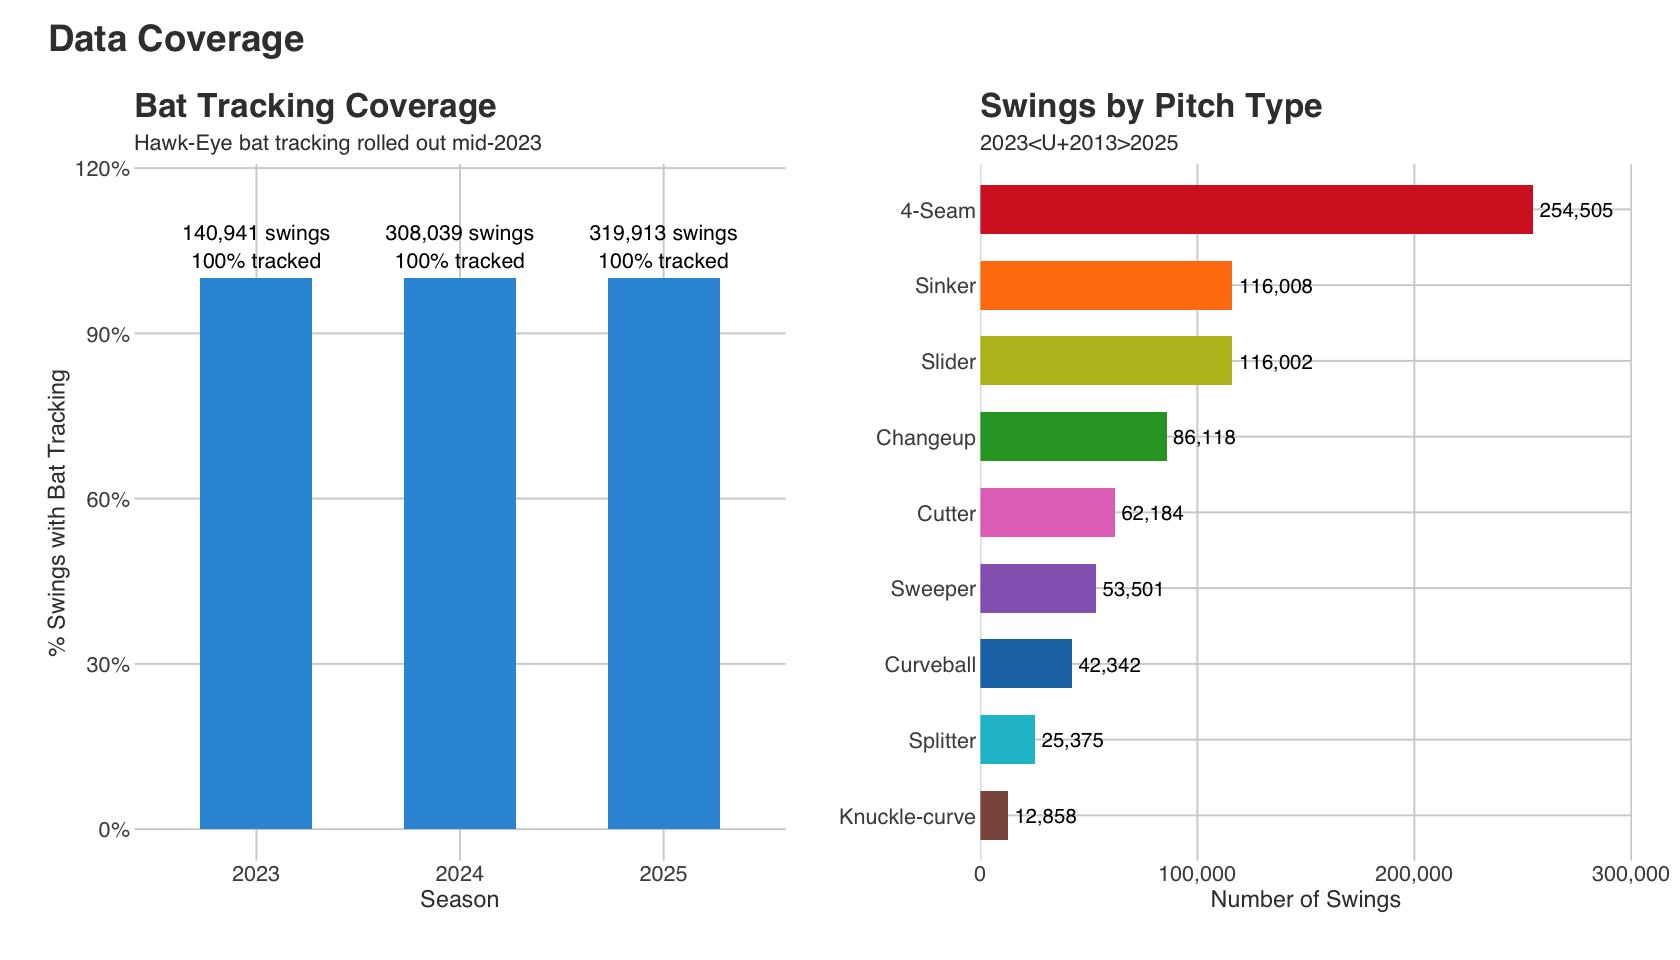

In [16]:
# ── Bat tracking coverage by year ─────────────────────────────────────────────
coverage <- df |>
  group_by(game_year) |>
  summarise(
    n_swings    = n(),
    n_tracked   = sum(!is.na(bat_speed)),
    pct_tracked = mean(!is.na(bat_speed)),
    .groups     = "drop"
  )

p1 <- ggplot(coverage, aes(x = factor(game_year), y = pct_tracked)) +
  geom_col(fill = "#3498db", width = 0.55) +
  geom_text(
    aes(label = sprintf("%s swings\n%.0f%% tracked",
                        formatC(n_swings, format = "d", big.mark = ","),
                        pct_tracked * 100)),
    vjust = -0.25, size = 4.5, lineheight = 1.1
  ) +
  scale_y_continuous(labels = percent_format(), limits = c(0, 1.15)) +
  labs(title = "Bat Tracking Coverage",
       subtitle = "Hawk-Eye bat tracking rolled out mid-2023",
       x = "Season", y = "% Swings with Bat Tracking")

# ── Pitch type distribution ────────────────────────────────────────────────────
pitch_dist <- df |>
  count(pitch_type) |>
  mutate(pitch_name = PITCH_NAMES[pitch_type]) |>
  arrange(desc(n))

p2 <- ggplot(pitch_dist,
             aes(x = reorder(pitch_name, n), y = n, fill = pitch_type)) +
  geom_col(width = 0.65) +
  geom_text(aes(label = formatC(n, format = "d", big.mark = ",")),
            hjust = -0.1, size = 4.3) +
  scale_fill_manual(values = PITCH_COLORS, guide = "none") +
  scale_y_continuous(expand = expansion(mult = c(0, 0.18)),
                     labels = comma_format()) +
  coord_flip() +
  labs(title = "Swings by Pitch Type",
       subtitle = "2023–2025",
       x = NULL, y = "Number of Swings")

p1 + p2 + plot_annotation(
  title = "Data Coverage",
  theme = theme(plot.title = element_text(size = 22, face = "bold"))
)


## Swing Outcomes

In [ ]:
# ── Swing outcome rates by pitch type ─────────────────────────────────────────
outcome_rates <- df |>
  group_by(pitch_name) |>
  summarise(
    n      = n(),
    whiff  = mean(outcome == "Whiff"),
    foul   = mean(outcome == "Foul"),
    bip    = mean(outcome == "BIP"),
    .groups = "drop"
  ) |>
  pivot_longer(c(whiff, foul, bip), names_to = "outcome", values_to = "rate") |>
  mutate(outcome = factor(outcome, levels = c("bip", "foul", "whiff"),
                          labels = c("Ball in Play", "Foul", "Whiff")))

p1 <- ggplot(outcome_rates,
             aes(x = reorder(pitch_name, -rate * (outcome == "Whiff")),
                 y = rate, fill = outcome)) +
  geom_col(width = 0.7) +
  scale_fill_manual(
    values = c("Ball in Play" = "#2ecc71", "Foul" = "#f39c12", "Whiff" = "#e74c3c"),
    name   = NULL
  ) +
  scale_y_continuous(labels = percent_format()) +
  labs(title = "Swing Outcome Rates by Pitch Type",
       x = NULL, y = "Rate") +
  theme(axis.text.x = element_text(angle = 30, hjust = 1),
        legend.position = "top")

# ── Overall outcome distribution ──────────────────────────────────────────────
overall <- df |>
  count(outcome) |>
  mutate(pct = n / sum(n))

p2 <- ggplot(overall, aes(x = outcome, y = pct,
                           fill = outcome)) +
  geom_col(width = 0.55) +
  geom_text(aes(label = sprintf("%.1f%%\n(%s)", pct * 100,
                                 formatC(n, format = "d", big.mark = ","))),
            vjust = -0.2, size = 4.5, lineheight = 1.1) +
  scale_fill_manual(
    values = c("BIP" = "#2ecc71", "Foul" = "#f39c12", "Whiff" = "#e74c3c"),
    guide  = "none"
  ) +
  scale_y_continuous(labels = percent_format(), limits = c(0, 0.55)) +
  labs(title = "Overall Swing Outcomes", x = NULL, y = "Rate")

p1 + p2 + plot_layout(widths = c(2, 1)) +
  plot_annotation(
    title = "Swing Outcome Structure",
    theme = theme(plot.title = element_text(size = 22, face = "bold"))
  )

## Plate Location

In [ ]:
# ── Plate location density by outcome ─────────────────────────────────────────
# Strike zone: x in [-0.83, 0.83], z in [1.5, 3.5] (approx league average)
sz <- data.frame(
  xmin = -0.83, xmax = 0.83, ymin = 1.5, ymax = 3.5
)

df |>
  filter(!is.na(plate_x), !is.na(plate_z),
         between(plate_x, -2.5, 2.5), between(plate_z, 0.5, 5)) |>
  ggplot(aes(x = plate_x, y = plate_z)) +
  stat_density_2d_filled(contour_var = "ndensity", bins = 12, alpha = 0.85) +
  geom_rect(data = sz, aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax),
            inherit.aes = FALSE, fill = NA, color = "white",
            linewidth = 0.8, linetype = "dashed") +
  facet_wrap(~ outcome, nrow = 1) +
  scale_fill_viridis_d(option = "magma", guide = "none") +
  coord_fixed() +
  labs(
    title    = "Plate Location by Swing Outcome",
    subtitle = "Dashed box = approximate strike zone  |  catcher's perspective",
    x        = "Horizontal location (ft, catcher's view)",
    y        = "Vertical location (ft)"
  )

## Count Profile

In [ ]:
# ── Swing volume and whiff rate by count ──────────────────────────────────────
count_profile <- df |>
  filter(balls <= 3, strikes <= 2) |>
  group_by(balls, strikes) |>
  summarise(
    n          = n(),
    whiff_rate = mean(outcome == "Whiff"),
    .groups    = "drop"
  ) |>
  mutate(
    count_label = sprintf("%d-%d", balls, strikes),
    count_type  = case_when(
      strikes == 2 & balls < 3 ~ "Two strikes",
      balls == 3 & strikes < 2 ~ "Three balls",
      balls == 3 & strikes == 2 ~ "Full",
      balls == 0 & strikes == 0 ~ "First pitch",
      TRUE                      ~ "Neutral"
    )
  )

p1 <- ggplot(count_profile,
             aes(x = factor(strikes), y = factor(balls), fill = n)) +
  geom_tile(color = "white", linewidth = 1) +
  geom_text(aes(label = sprintf("%s\n%.0f%%",
                                 formatC(n, format = "d", big.mark = ","),
                                 whiff_rate * 100)),
            size = 4.5, color = "white", fontface = "bold", lineheight = 1.2) +
  scale_fill_gradient(low = "#3498db", high = "#c0392b",
                      name = "Swings", labels = comma_format()) +
  scale_x_discrete(labels = c("0 K", "1 K", "2 K")) +
  scale_y_discrete(labels = c("0 BB", "1 BB", "2 BB", "3 BB")) +
  labs(title = "Swing Volume & Whiff Rate by Count",
       subtitle = "Count: balls-strikes  |  Cell text: swing count + whiff%",
       x = "Strikes", y = "Balls")

p2 <- ggplot(count_profile,
             aes(x = reorder(count_label, whiff_rate), y = whiff_rate,
                 fill = count_type)) +
  geom_col(width = 0.65) +
  geom_text(aes(label = sprintf("%.1f%%", whiff_rate * 100)),
            hjust = -0.1, size = 4.3) +
  scale_y_continuous(labels = percent_format(), expand = expansion(mult = c(0, 0.18))) +
  scale_fill_brewer(palette = "Set2", name = NULL) +
  coord_flip() +
  labs(title = "Whiff Rate by Count", x = NULL, y = "Whiff rate") +
  theme(legend.position = "top")

p1 + p2 + plot_annotation(
  title = "Count Profile",
  theme = theme(plot.title = element_text(size = 22, face = "bold"))
)

## Bat Speed & Swing Metrics

In [ ]:
# ── Bat speed and swing length distributions ──────────────────────────────────
tracked <- df |> filter(!is.na(bat_speed), !is.na(swing_length))

p1 <- ggplot(tracked, aes(x = bat_speed, fill = outcome, color = outcome)) +
  geom_density(alpha = 0.25, linewidth = 0.9) +
  scale_fill_manual(
    values = c("BIP" = "#2ecc71", "Foul" = "#f39c12", "Whiff" = "#e74c3c"),
    name = NULL
  ) +
  scale_color_manual(
    values = c("BIP" = "#2ecc71", "Foul" = "#f39c12", "Whiff" = "#e74c3c"),
    name = NULL
  ) +
  labs(title = "Bat Speed by Outcome",
       x = "Bat speed (mph)", y = "Density") +
  theme(legend.position = "top")

p2 <- ggplot(tracked, aes(x = swing_length, fill = outcome, color = outcome)) +
  geom_density(alpha = 0.25, linewidth = 0.9) +
  scale_fill_manual(
    values = c("BIP" = "#2ecc71", "Foul" = "#f39c12", "Whiff" = "#e74c3c"),
    name = NULL
  ) +
  scale_color_manual(
    values = c("BIP" = "#2ecc71", "Foul" = "#f39c12", "Whiff" = "#e74c3c"),
    name = NULL
  ) +
  labs(title = "Swing Length by Outcome",
       x = "Swing length (ft)", y = "Density") +
  theme(legend.position = "top")

# ── Bat speed vs swing length scatter (sample) ────────────────────────────────
set.seed(42)
samp <- slice_sample(tracked, n = 20000)

p3 <- ggplot(samp, aes(x = swing_length, y = bat_speed, color = outcome)) +
  geom_point(alpha = 0.08, size = 0.6) +
  scale_color_manual(
    values = c("BIP" = "#2ecc71", "Foul" = "#f39c12", "Whiff" = "#e74c3c"),
    name = NULL, guide = "none"
  ) +
  labs(title = "Bat Speed vs Swing Length",
       subtitle = "20k sample",
       x = "Swing length (ft)", y = "Bat speed (mph)")

(p1 + p2) / p3 + plot_annotation(
  title = "Bat-Tracking Metrics",
  subtitle = sprintf("Bat-tracked swings only  (n = %s)",
                     formatC(nrow(tracked), format = "d", big.mark = ",")),
  theme = theme(
    plot.title    = element_text(size = 22, face = "bold"),
    plot.subtitle = element_text(size = 13)
  )
)